# Bixby analysis — MindEye2 eval

Evaluates each subject's pre-trained MindEye2 model on the MST pairs (2AFC A vs B), for every
combination of `SUBS` × `EVAL_TYPES` in the config cell.

* Results are stored in one long-format CSV (`RESULTS_CSV`), one row per (sub, eval_type, session, task, run).
* Results are written after **each** (sub, eval_type) finishes, so an interrupted run loses at most one eval.
* Any (sub, eval_type) already in the CSV is **skipped** — just add subjects to the list and re-run.
  Set `FORCE_RERUN = True` to recompute (old rows for that combination are replaced, not duplicated).

In [1]:
import os
import sys
import pickle
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.stats import zscore

import torch
import torch.nn as nn
from torchvision import transforms
import imageio.v2 as imageio

import utils
import bixby_utils

In [2]:
%load_ext autoreload
%autoreload 2

## Config

In [14]:
# ---- What to run ----
SUBS = ['sub-03', 'sub-04', 'sub-06', 'sub-07', 'sub-08']
EVAL_TYPES = ['run_task_split', 'task_split']  # see "Eval definitions" below
RUN_EMBEDDINGS = False                         # also save per-run CLIP-space similarities/projections (one CSV per sub)
FORCE_RERUN = False                            # True -> recompute even if results already exist

# ---- Paths ----
data_folder = '/scratch/gpfs/KNORMAN/bixby_beta_outputs/'
img_folder = '/scratch/gpfs/KNORMAN/wanjia/mindeye_testing/real_time_mindEye2/pilot_bixby_data/'
outdir_folder = '/scratch/gpfs/KNORMAN/bixby_beta_outputs/mindeye_outputs/'
RESULTS_CSV = 'bixby_data/mindeye_eval_results.csv'
EMBEDDINGS_DIR = 'csv'

# Checkpoint folder per subject
model_folders = {
    'sub-03': 'output_sub-03_sub-03_2-session_task-mindeye_3bixby-main_use-two-session_afni_avgrepeats_2session-mask_150epochs_1793590051.6748135',
    'sub-04': 'output_sub-04_sub-04_2-session_task-mindeye_4bixby-main_use-two-session_afni_avgrepeats_2session-mask_150epochs_1793590063.9716845',
    'sub-06': 'output_sub-06_sub-06_2-session_task-mindeye_6bixby-main_use-two-session_afni_avgrepeats_2session-mask_150epochs_1793814757.9350307',
    'sub-07': 'output_sub-07_sub-07_2-session_task-mindeye_7bixby-main_use-two-session_afni_avgrepeats_2session-mask_150epochs_1793905708.7470028',
    'sub-08': 'output_sub-08_sub-08_2-session_task-mindeye_8bixby-main_use-two-session_afni_avgrepeats_2session-mask_150epochs_1793814757.933323',
}

# ---- Data layout ----
sessions = ['ses-03', 'ses-04']
tasks = ['study', 'test', 'snap']
test_images = [f'A_{i}' for i in range(1, 19)] + [f'B_{i}' for i in range(1, 19)]
pairs = [[test_images.index(f'A_{i}'), test_images.index(f'B_{i}')] for i in range(1, 19)]

# ---- Model architecture (must match training) ----
n_blocks = 4
hidden_dim = 1024
use_prior = True
clip_scale = 1.
clip_seq_dim = 256
clip_emb_dim = 1664

SEED = 315  # eval is deterministic; this only fixes the init of any weights missing from a checkpoint

## Setup (run once): device, CLIP image embedder, test images

In [4]:
from accelerate import Accelerator

local_rank = int(os.getenv('RANK', 0))
accelerator = Accelerator(split_batches=False)
device = accelerator.device

if accelerator.mixed_precision == "bf16":
    data_type = torch.bfloat16
elif accelerator.mixed_precision == "fp16":
    data_type = torch.float16
else:
    data_type = torch.float32

print("PID =", os.getpid(), "| device =", device, "| local rank =", local_rank, "| data_type =", data_type)
print = accelerator.print  # only print if local_rank=0

torch.backends.cuda.matmul.allow_tf32 = True  # tf32 is faster than standard float32
utils.seed_everything(SEED)

PID = 1014866 | device = cuda | local rank = 0 | data_type = torch.float32


In [5]:
sys.path.append('generative_models/')
import sgm
from generative_models.sgm.modules.encoders.modules import FrozenOpenCLIPImageEmbedder

try:
    clip_img_embedder
except NameError:
    clip_img_embedder = FrozenOpenCLIPImageEmbedder(
        arch="ViT-bigG-14",
        version="laion2b_s39b_b160k",
        output_tokens=True,
        only_tokens=True,
    )
    clip_img_embedder.to(device)
clip_img_embedder.model.visual.set_grad_checkpointing(True)

In [6]:
resize_transform = transforms.Resize((224, 224))
root_dir = os.path.join(img_folder, 'stimuli', 'scenes')

imgs = []
for img in test_images:
    img_list, img_id = img.split('_')[0], int(img.split('_')[1])
    image_file = f'{root_dir}/list{img_list}/{img_id:02d}.png'
    if not os.path.exists(image_file):
        raise FileNotFoundError(f'Cannot find the image at this path {image_file}')
    im = torch.Tensor(imageio.imread(image_file) / 255).permute(2, 0, 1)
    imgs.append(resize_transform(im.unsqueeze(0)))
test_img_tensor = torch.vstack(imgs)
print("testing images", test_img_tensor.shape)

/home/wg7536/.conda/envs/rt_mindEye2/lib/python3.11/site-packages/torchvision/transforms/functional.py:1603: UserWarning: The default value of the antialias parameter of all the resizing transforms (Resize(), RandomResizedCrop(), etc.) will change from None to True in v0.17, in order to be consistent across the PIL and Tensor backends. To suppress this warning, directly pass antialias=True (recommended, future default), antialias=None (current default, which means False for Tensors and True for PIL), or antialias=False (only works on Tensors - PIL will still use antialiasing). This also applies if you are using the inference transforms from the models weights: update the call to weights.transforms(antialias=True).
  warnings.warn(


testing images torch.Size([36, 3, 224, 224])


In [7]:
@torch.no_grad()
def embed_images(images):
    """Normalized CLIP embedding of each image. Images don't depend on subject, so this runs once."""
    out = []
    with torch.cuda.amp.autocast(dtype=data_type):
        for i in range(len(images)):
            emb = clip_img_embedder(images[i].to(device)[None].float())
            out.append(nn.functional.normalize(emb.flatten(1), dim=-1))
    return out

image_embs = embed_images(test_img_tensor)
print(len(image_embs), image_embs[0].shape)

/home/wg7536/.conda/envs/rt_mindEye2/lib/python3.11/site-packages/torch/utils/checkpoint.py:429: UserWarning: torch.utils.checkpoint: please pass in use_reentrant=True or use_reentrant=False explicitly. The default value of use_reentrant will be updated to be False in the future. To maintain current behavior, pass use_reentrant=True. It is recommended that you use use_reentrant=False. Refer to docs for more details on the differences between the two variants.
  warnings.warn(
/home/wg7536/.conda/envs/rt_mindEye2/lib/python3.11/site-packages/torch/utils/checkpoint.py:61: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  warnings.warn(


36 torch.Size([1, 425984])


## Data loading

In [8]:
def load_subject_data(sub):
    """Load ROI data, apply the union mask and z-score each session/task."""
    with open(os.path.join(data_folder, f'{sub}_roi_vox_all_sessions.pkl'), 'rb') as f:
        sub_dic = pickle.load(f)
    union_mask = sub_dic['union_mask']
    print(f'{sub}: NSD mask size {union_mask.shape}, union mask size {sum(union_mask)}')
    for ses in sessions:
        for task in tasks:
            roi = sub_dic[ses][task]['roi'][:, union_mask]
            sub_dic[ses][task]['roi'] = np.nan_to_num(zscore(roi, axis=0))
            print(f'  {ses} {task}: {sub_dic[ses][task]["roi"].shape}')
    return sub_dic


def build_test_data(sub_dic):
    """Repeats averaged across ALL runs: test_data[ses][task], plus 'all_task' (mean of the tasks)."""
    test_data = {}
    for ses in sessions:
        test_data[ses] = {}
        for task in tasks:
            sd = sub_dic[ses][task]
            repeat_idx, _ = bixby_utils.locate_repeat_index_per_run(sd, test_images)
            test_data[ses][task] = bixby_utils.average_repeats_across_run(sd['roi'], repeat_idx, test_images)
        test_data[ses]['all_task'] = np.mean([test_data[ses][t] for t in tasks], axis=0)
    return test_data


def build_per_run_data(sub_dic):
    """Repeats averaged within each run: per_run[ses][task][run], plus 'all_task' (mean of the tasks per run)."""
    per_run = {}
    for ses in sessions:
        per_run[ses] = {}
        for task in tasks:
            sd = sub_dic[ses][task]
            _, per_run_repeat_idx = bixby_utils.locate_repeat_index_per_run(sd, test_images)
            per_run[ses][task] = bixby_utils.average_repeats_for_each_run(sd['roi'], per_run_repeat_idx, test_images)
        per_run[ses]['all_task'] = {
            run: np.mean([per_run[ses][t][run] for t in tasks], axis=0)
            for run in per_run[ses][tasks[-1]].keys()
        }
    return per_run

## Model loading

In [16]:
def load_model(sub_dic, model_dir):
    num_voxels_list = [sub_dic[sessions[0]][tasks[0]]['roi'].shape[-1]]
    model = utils.prepare_model_and_training(
        num_voxels_list=num_voxels_list,
        n_blocks=n_blocks,
        hidden_dim=hidden_dim,
        clip_emb_dim=clip_emb_dim,
        clip_seq_dim=clip_seq_dim,
        use_prior=use_prior,
        clip_scale=clip_scale,
    )
    ckpt_path = os.path.join(model_dir, 'last_clipped.pth')
    print(f"---loading {ckpt_path}---")
    checkpoint = torch.load(ckpt_path, map_location='cpu')
    missing, unexpected = model.load_state_dict(checkpoint['model_state_dict'], strict=False)
    del checkpoint
    if missing or unexpected:
        print(f"  missing keys: {len(missing)}, unexpected keys: {len(unexpected)}")
    torch.cuda.empty_cache()
    return model.to(device).eval()

## Eval functions

In [10]:
def to_tensor(vox):
    vox = torch.as_tensor(np.asarray(vox)).float()
    assert len(vox) == len(test_images), (len(vox), len(test_images))
    return vox


@torch.no_grad()
def embed_voxels(model, vox):
    """Normalized CLIP-space embedding predicted from each image's voxel pattern."""
    out = []
    with torch.cuda.amp.autocast(dtype=data_type):
        for i in range(len(vox)):
            voxel = vox[i].to(device)[None].unsqueeze(1)
            voxel_ridge = model.ridge(voxel, 0)
            _, clip_voxels, _ = model.backbone(voxel_ridge)
            out.append(nn.functional.normalize(clip_voxels.flatten(1), dim=-1))
    return out


def evaluate_MST(model, vox, pairs):
    """2AFC: for each pair, is voxel A closer to image A than to image B (and vice versa)?"""
    vox_embs = embed_voxels(model, vox)
    score, total, output = 0, 0, []
    for a, b in pairs:
        sim = utils.batchwise_cosine_similarity
        correct_a = int(sim(vox_embs[a], image_embs[a]) > sim(vox_embs[a], image_embs[b]))
        correct_b = int(sim(vox_embs[b], image_embs[b]) > sim(vox_embs[b], image_embs[a]))
        output += [[a, correct_a], [b, correct_b]]
        score += correct_a + correct_b
        total += 2
    return score, total, score / total, output


def calculate_projection(imageA, imageB, voxelA, voxelB):
    diff_image = imageB - imageA
    standard_diff = diff_image / np.sqrt(np.dot(diff_image, diff_image.T))
    distanceA = np.dot(standard_diff, (voxelA - imageA).T)
    distanceB = np.dot(standard_diff, (voxelB - imageA).T)
    return distanceA, distanceB


EMBEDDING_ROWS = ['imageA-imageB', 'imageA-voxelA', 'imageA-voxelB',
                  'imageB-voxelA', 'imageB-voxelB', 'voxelA-voxelB',
                  'voxelA-imageA_distance', 'voxelB-imageA_distance']

def get_MST_embeddings(model, vox, pairs):
    """Per pair: cosine similarities between images/voxels and projections onto the A->B image axis."""
    vox_embs = embed_voxels(model, vox)
    sim = lambda x, y: utils.batchwise_cosine_similarity(x, y).item()
    output = {}
    for a, b in pairs:
        iA, iB, vA, vB = image_embs[a], image_embs[b], vox_embs[a], vox_embs[b]
        distanceA, distanceB = calculate_projection(iA.detach().cpu(), iB.detach().cpu(),
                                                    vA.detach().cpu(), vB.detach().cpu())
        output[a] = [sim(iA, iB), sim(iA, vA), sim(iA, vB), sim(iB, vA), sim(iB, vB), sim(vA, vB),
                     distanceA.item(), distanceB.item()]
    return output

### Eval definitions

Each eval type returns a list of rows `{session, task, run, score, total, accuracy}`.
`task` includes `'all_task'` (voxels averaged over study/test/snap).

* `run_task_split` — every session × task × run (repeats averaged within the run).
* `task_split` — every session × task, repeats averaged across all runs (`run = 'all'`).
  The `all_task` row of this is the old "average all" number.

To add a new eval, add a branch here and its name to `EVAL_TYPES`.

In [11]:
def run_eval(eval_type, model, per_run, test_data):
    rows = []
    for ses in sessions:
        for task in tasks + ['all_task']:
            if eval_type == 'run_task_split':
                items = per_run[ses][task].items()
            elif eval_type == 'task_split':
                items = [('all', test_data[ses][task])]
            else:
                raise ValueError(f'Unknown eval_type {eval_type!r}')
            for run, vox in items:
                score, total, acc, _ = evaluate_MST(model, to_tensor(vox), pairs)
                rows.append(dict(session=ses, task=task, run=run, score=score, total=total, accuracy=acc))
    return rows

## Results storage

In [12]:
KEY_COLS = ['sub', 'eval_type']
ROW_COLS = KEY_COLS + ['session', 'task', 'run']
RESULT_COLS = ROW_COLS + ['score', 'total', 'accuracy', 'model_dir', 'timestamp']


def load_results():
    if not os.path.exists(RESULTS_CSV):
        return pd.DataFrame(columns=RESULT_COLS)
    results = pd.read_csv(RESULTS_CSV, dtype={'sub': str, 'run': str})
    if 'seed' in results.columns:
        # Older multi-seed file: seeds gave identical results, so keep one copy of each row.
        results = results.drop(columns='seed').drop_duplicates(subset=ROW_COLS, ignore_index=True)
    return results[RESULT_COLS]


def completed_keys(results):
    return set(results[KEY_COLS].drop_duplicates().itertuples(index=False, name=None))


def save_results(new_rows, sub, eval_type):
    """Replace any existing rows for (sub, eval_type) with new_rows; write atomically."""
    results = load_results()
    same = (results['sub'] == sub) & (results['eval_type'] == eval_type)
    new = pd.DataFrame(new_rows).assign(sub=sub, eval_type=eval_type)
    if results.empty:
        results = new[RESULT_COLS]
    else:
        results = pd.concat([results[~same], new[RESULT_COLS]], ignore_index=True)
    os.makedirs(os.path.dirname(RESULTS_CSV) or '.', exist_ok=True)
    tmp = RESULTS_CSV + '.tmp'
    results.to_csv(tmp, index=False)
    os.replace(tmp, RESULTS_CSV)


def embeddings_path(sub):
    return os.path.join(EMBEDDINGS_DIR, f'{sub}_cpd_by_run.csv')


def save_embeddings(model, per_run, sub):
    dfs = []
    for ses in sessions:
        for run, vox in per_run[ses]['all_task'].items():
            df = pd.DataFrame(get_MST_embeddings(model, to_tensor(vox), pairs))
            df.insert(0, 'type', EMBEDDING_ROWS)
            dfs.append(df.assign(session=ses, run=run, sub=sub))
    os.makedirs(EMBEDDINGS_DIR, exist_ok=True)
    pd.concat(dfs, ignore_index=True).to_csv(embeddings_path(sub), index=False)

## Run all evals

Loops over subjects (data and model loaded once per subject), skipping anything already in `RESULTS_CSV`.

In [17]:
done = set() if FORCE_RERUN else completed_keys(load_results())

for sub in SUBS:
    evals = [e for e in EVAL_TYPES if (sub, e) not in done]
    need_emb = RUN_EMBEDDINGS and (FORCE_RERUN or not os.path.exists(embeddings_path(sub)))
    if not (evals or need_emb):
        print(f'[skip] {sub}: nothing to run')
        continue
    if sub not in model_folders:
        print(f'[skip] {sub}: no model folder configured in model_folders')
        continue

    sub_dic = load_subject_data(sub)
    per_run = build_per_run_data(sub_dic)
    test_data = build_test_data(sub_dic)
    model_dir = os.path.join(outdir_folder, model_folders[sub])
    model = load_model(sub_dic, model_dir)

    for eval_type in evals:
        print(f'[run] {sub} {eval_type}')
        rows = run_eval(eval_type, model, per_run, test_data)
        stamp = datetime.now().isoformat(timespec='seconds')
        for r in rows:
            r.update(model_dir=model_dir, timestamp=stamp)
        save_results(rows, sub, eval_type)
        print(f'      mean accuracy = {np.mean([r["accuracy"] for r in rows]):.3f}')

    if need_emb:
        print(f'[run] {sub} embeddings')
        save_embeddings(model, per_run, sub)

    del model, sub_dic, per_run, test_data
    torch.cuda.empty_cache()

print('Done.')

[skip] sub-03: nothing to run
[skip] sub-04: nothing to run
[skip] sub-06: nothing to run
sub-07: NSD mask size (17009,), union mask size 2516
  ses-03 study: (216, 2516)
  ses-03 test: (216, 2516)
  ses-03 snap: (432, 2516)
  ses-04 study: (108, 2516)
  ses-04 test: (108, 2516)
  ses-04 snap: (216, 2516)
MindEyeModule()
param counts:
2,577,408 total
2,577,408 trainable
param counts:
2,577,408 total
2,577,408 trainable
param counts:
453,360,280 total
453,360,280 trainable
param counts:
455,937,688 total
455,937,688 trainable
param counts:
259,865,216 total
259,865,200 trainable
param counts:
715,802,904 total
715,802,888 trainable
---loading /scratch/gpfs/KNORMAN/bixby_beta_outputs/mindeye_outputs/output_sub-07_sub-07_2-session_task-mindeye_7bixby-main_use-two-session_afni_avgrepeats_2session-mask_150epochs_1793905708.7470028/last_clipped.pth---
[run] sub-07 run_task_split
      mean accuracy = 0.583
[run] sub-07 task_split
      mean accuracy = 0.622
[skip] sub-08: nothing to run
Done

## Results

In [18]:
results = load_results()
print(results.groupby('sub')['eval_type'].unique())
results.head()

sub
sub-03    [run_task_split, task_split]
sub-04    [run_task_split, task_split]
sub-06    [run_task_split, task_split]
sub-07    [run_task_split, task_split]
sub-08    [run_task_split, task_split]
Name: eval_type, dtype: object


,sub,eval_type,session,task,run,score,total,accuracy,model_dir,timestamp
0,sub-03,run_task_split,ses-03,study,run-01,21,36,0.583333,/scratch/gpfs/KNORMAN/bixby_beta_outputs/minde...,2026-11-05T14:50:50
1,sub-03,run_task_split,ses-03,study,run-02,19,36,0.527778,/scratch/gpfs/KNORMAN/bixby_beta_outputs/minde...,2026-11-05T14:50:50
2,sub-03,run_task_split,ses-03,study,run-03,23,36,0.638889,/scratch/gpfs/KNORMAN/bixby_beta_outputs/minde...,2026-11-05T14:50:50
3,sub-03,run_task_split,ses-03,study,run-04,23,36,0.638889,/scratch/gpfs/KNORMAN/bixby_beta_outputs/minde...,2026-11-05T14:50:50
4,sub-03,run_task_split,ses-03,study,run-05,24,36,0.666667,/scratch/gpfs/KNORMAN/bixby_beta_outputs/minde...,2026-11-05T14:50:50


In [19]:
# Wide tables in the old layout: rows = session.task.run, columns = sub
def wide_table(eval_type):
    r = results[results['eval_type'] == eval_type]
    return r.pivot_table(index=['session', 'task', 'run'], columns='sub', values='accuracy')

run_task_wide = wide_table('run_task_split')
task_wide = wide_table('task_split')

run_task_wide.to_csv('bixby_data/run_task_split.csv')
task_wide.to_csv('bixby_data/task_split.csv')
task_wide

sub                     sub-03    sub-04    sub-06    sub-07    sub-08
session task     run                                                  
ses-03  all_task all  0.777778  0.750000  0.583333  0.833333  0.694444
        snap     all  0.805556  0.694444  0.638889  0.444444  0.638889
        study    all  0.694444  0.694444  0.555556  0.694444  0.527778
        test     all  0.750000  0.638889  0.694444  0.777778  0.722222
ses-04  all_task all  0.583333  0.666667  0.611111  0.611111  0.694444
        snap     all  0.666667  0.611111  0.722222  0.583333  0.750000
        study    all  0.527778  0.638889  0.583333  0.527778  0.583333
        test     all  0.638889  0.527778  0.527778  0.500000  0.638889

## Figures

In [27]:
MAX_COLS = 4

In [20]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

%matplotlib inline

TYPE_ORDER = ["study", "test", "snap", "all_task"]
TYPE_COLS = {"study": "#E69F00", "test": "#56B4E9", "snap": "#009E73", "all_task": "#CC79A7"}
SES_COLS = {"ses-03": "#222222", "ses-04": "#B2182B"}

# ggplot2 theme_bw-like defaults
plt.rcParams.update({
    "font.size": 12,
    "axes.edgecolor": "#333333",
    "axes.grid": True,
    "grid.color": "#EBEBEB",
    "axes.axisbelow": True,
    "xtick.color": "#4D4D4D",
    "ytick.color": "#4D4D4D",
})


def load_data(path):
    """Read the wide CSV (one column per subject) and return it in long format."""
    raw = pd.read_csv(path)
    subjects = [c for c in raw.columns if c.startswith("sub-")]
    df = raw.melt(id_vars=["session", "task", "run"], value_vars=subjects,
                  var_name="subject", value_name="accuracy")
    df = df.rename(columns={"task": "type"})
    df["ses_num"] = df["session"].str.replace("ses-", "").astype(int)
    df["run_num"] = df["run"].str.replace("run-", "").astype(int)
    df["run_label"] = [f"ses{s:02d}-{r}" for s, r in zip(df["ses_num"], df["run_num"])]
    return df


def _as_list(x):
    return [x] if isinstance(x, str) else x


def _filter(df, types=None, sessions=None, subjects=None):
    """Keep only the requested types / sessions / subjects; check the names exist."""
    for col, wanted in [("type", types), ("session", sessions), ("subject", subjects)]:
        wanted = _as_list(wanted)
        if wanted is None:
            continue
        missing = set(wanted) - set(df[col])
        if missing:
            raise ValueError(f"Unknown {col}(s) {sorted(missing)}; available: {sorted(df[col].unique())}")
        df = df[df[col].isin(wanted)]
    return df


def _y_range(d):
    """Default 0.3-0.9, widened to the nearest 0.1 if any value falls outside."""
    lo = min(0.3, np.floor(d["accuracy"].min() * 10) / 10)
    hi = max(0.9, np.ceil(d["accuracy"].max() * 10) / 10)
    return lo, hi


def _strip(ax, text, side):
    """Grey facet strip label like ggplot's facet_grid."""
    kw = dict(transform=ax.transAxes, fontweight="bold", ha="center", va="center",
              bbox=dict(boxstyle="square,pad=0.4", fc="#D9D9D9", ec="#333333"))
    if side == "right":
        ax.text(1.02, 0.5, text, rotation=-90, **kw)
    else:
        ax.text(0.5, 1.04, text, **kw)


def _subjects_in(d):
    return list(dict.fromkeys(d["subject"]))  # keeps CSV column order


def _save(fig, save_as):
    if save_as:
        Path(OUT_DIR).mkdir(exist_ok=True)
        fig.savefig(Path(OUT_DIR) / save_as, dpi=300)


def _title_suffix(types, sessions):
    parts = []
    if types is not None:
        parts.append(", ".join(_as_list(types)))
    if sessions is not None:
        parts.append(", ".join(_as_list(sessions)))
    return f" ({'; '.join(parts)})" if parts else ""


def plot_accuracy_by_run(df, types=None, sessions=None, subjects=None, save_as=None):
    """Line plot: accuracy per run, one row per subject, colour = task type."""
    d = _filter(df, types, sessions, subjects)
    subs = _subjects_in(d)
    tys = [t for t in TYPE_ORDER if t in set(d["type"])]
    runs = (d[["ses_num", "run_num", "run_label"]].drop_duplicates()
            .sort_values(["ses_num", "run_num"]))
    run_pos = {lab: i for i, lab in enumerate(runs["run_label"])}
    d = d.assign(x=d["run_label"].map(run_pos))
    y_lo, y_hi = _y_range(d)
    # session dividers between consecutive sessions
    breaks = d.groupby("ses_num")["x"].max().sort_index().iloc[:-1] + 0.5

    header_in = 1.3
    fig_h = 2.3 * len(subs) + header_in
    fig, axes = plt.subplots(len(subs), 1, figsize=(9, fig_h), sharex=True, sharey=True,
                             squeeze=False)
    axes = axes[:, 0]
    for ax, sub in zip(axes, subs):
        ds = d[d["subject"] == sub]
        ax.axhline(0.5, ls="--", color="grey", lw=1)
        for b in breaks:
            ax.axvline(b, color="#B3B3B3", lw=1)
        for t in tys:
            for _, g in ds[ds["type"] == t].groupby("session"):  # break line between sessions
                g = g.sort_values("x")
                ax.plot(g["x"], g["accuracy"], "-o", color=TYPE_COLS[t], lw=1.6, ms=6)
        ax.set_ylim(y_lo - 0.03, y_hi + 0.03)
        ax.set_yticks(np.arange(y_lo, y_hi + 0.001, 0.1))
        _strip(ax, sub, "right")
    axes[-1].set_xticks(range(len(run_pos)))
    axes[-1].set_xticklabels(list(run_pos), rotation=45, ha="right")
    axes[-1].set_xlim(-0.5, len(run_pos) - 0.5)
    fig.supxlabel("Run")
    fig.supylabel("Accuracy")
    fig.suptitle("Accuracy by run" + _title_suffix(types, sessions), x=0.02,
                 y=1 - 0.15 / fig_h, ha="left", va="top", fontsize=16)
    handles = [Line2D([], [], color=TYPE_COLS[t], marker="o", lw=1.6, label=t) for t in tys]
    fig.legend(handles=handles, title="Type", loc="upper center", ncol=len(tys),
               bbox_to_anchor=(0.5, 1 - 0.4 / fig_h), frameon=False)
    fig.tight_layout(rect=(0, 0, 0.97, 1 - header_in / fig_h))
    _save(fig, save_as)
    plt.close(fig)  # Jupyter shows the returned figure once
    return fig


def plot_mean_by_type(df, types=None, sessions=None, subjects=None, save_as=None, seed=1):
    """Bar plot: mean accuracy per task type, one panel per subject, dots = runs by session."""
    d = _filter(df, types, sessions, subjects)
    subs = _subjects_in(d)
    tys = [t for t in TYPE_ORDER if t in set(d["type"])]
    sess = sorted(d["session"].unique())
    _, y_hi = _y_range(d)
    summ = (d.groupby(["subject", "type"])["accuracy"]
              .agg(mean="mean", se=lambda s: s.std(ddof=1) / np.sqrt(len(s)))
              .reset_index())
    n_runs = d.groupby(["subject", "type"]).size().max()

    rng = np.random.default_rng(seed)
    subtitle = (f"Bars: mean over {n_runs} runs ({' + '.join(sess)}); error bars: ±1 SE; "
                "dots: individual runs coloured by session")
    legend_handles = [Line2D([], [], ls="", marker="o", color=SES_COLS[s], mec="white", ms=8,
                             label=s) for s in sess]

    if len(tys) == 1:
        # Single type: one panel, subjects along the x-axis
        t = tys[0]
        header_in = 1.6
        fig_h = 4.5 + header_in
        fig, ax = plt.subplots(figsize=(max(1.2 * len(subs) + 1.5, 9), fig_h))
        s = summ.set_index("subject").loc[subs]
        xs = np.arange(len(subs))
        ax.bar(xs, s["mean"], width=0.7, color=TYPE_COLS[t], alpha=0.6, zorder=2)
        ax.errorbar(xs, s["mean"], yerr=s["se"], fmt="none", ecolor="black",
                    capsize=5, lw=1.2, zorder=3)
        for i, sub in enumerate(subs):
            pts = d[d["subject"] == sub]
            jitter = rng.uniform(-0.15, 0.15, len(pts))
            ax.scatter(i + jitter, pts["accuracy"], c=pts["session"].map(SES_COLS),
                       s=36, edgecolors="white", linewidths=1, zorder=4)
            ax.text(i, 0.02, f"{s.loc[sub, 'mean']:.2f}", ha="center", va="bottom",
                    fontweight="bold", color="#1A1A1A", zorder=5)
        ax.axhline(0.5, ls="--", color="#4D4D4D", lw=1, zorder=3)
        ax.set_xticks(xs)
        ax.set_xticklabels(subs)
        ax.set_ylim(0, y_hi + 0.02)
        ax.set_yticks(np.arange(0, y_hi + 0.001, 0.1))
        ax.grid(axis="x", visible=False)
        ax.set_xlabel("Subject")
        ax.set_ylabel("Accuracy")
        fig.suptitle(f"Mean accuracy by subject ({t}"
                     + (f"; {', '.join(_as_list(sessions))}" if sessions is not None else "") + ")",
                     x=0.01, y=1 - 0.2 / fig_h, ha="left", va="top", fontsize=16)
        fig.text(0.01, 1 - 0.6 / fig_h, subtitle, ha="left", va="top", fontsize=12)
        fig.legend(handles=legend_handles, title="Session (individual runs)", loc="upper center",
                   ncol=len(sess), bbox_to_anchor=(0.5, 1 - 0.85 / fig_h), frameon=False)
        fig.tight_layout(rect=(0, 0, 1, 1 - header_in / fig_h))
        _save(fig, save_as)
        plt.close(fig)
        return fig

    ncols = min(len(subs), MAX_COLS)
    nrows = int(np.ceil(len(subs) / ncols))
    header_in = 1.6
    fig_h = 4 * nrows + header_in
    bar_w = 0.75 * len(tys) + 0.5  # panel width scales with the number of bars
    fig, axes = plt.subplots(nrows, ncols, figsize=(max(bar_w * ncols, 6), fig_h),
                             sharey=True, squeeze=False)
    for ax in axes.flat[len(subs):]:
        ax.set_visible(False)
    for ax, sub in zip(axes.flat, subs):
        s = summ[summ["subject"] == sub].set_index("type").loc[tys]
        xs = np.arange(len(tys))
        ax.bar(xs, s["mean"], width=0.7, color=[TYPE_COLS[t] for t in tys], alpha=0.6, zorder=2)
        ax.errorbar(xs, s["mean"], yerr=s["se"], fmt="none", ecolor="black",
                    capsize=5, lw=1.2, zorder=3)
        for i, t in enumerate(tys):
            pts = d[(d["subject"] == sub) & (d["type"] == t)]
            jitter = rng.uniform(-0.15, 0.15, len(pts))
            ax.scatter(i + jitter, pts["accuracy"], c=pts["session"].map(SES_COLS),
                       s=36, edgecolors="white", linewidths=1, zorder=4)
            ax.text(i, 0.02, f"{s.loc[t, 'mean']:.2f}", ha="center", va="bottom",
                    fontweight="bold", color="#1A1A1A", zorder=5)
        ax.axhline(0.5, ls="--", color="#4D4D4D", lw=1, zorder=3)
        ax.set_xticks(xs)
        ax.set_xticklabels(tys)
        ax.set_xlim(-0.6, len(tys) - 0.4)
        ax.set_ylim(0, y_hi + 0.02)
        ax.set_yticks(np.arange(0, y_hi + 0.001, 0.1))
        ax.grid(axis="x", visible=False)
        _strip(ax, sub, "top")
    for row in axes:
        row[0].set_ylabel("Accuracy")
    fig.supxlabel("Type")
    fig.suptitle("Mean accuracy by type" + _title_suffix(types, sessions), x=0.01,
                 y=1 - 0.2 / fig_h, ha="left", va="top", fontsize=16)
    fig.text(0.01, 1 - 0.6 / fig_h, subtitle, ha="left", va="top", fontsize=12)
    fig.legend(handles=legend_handles, title="Session (individual runs)", loc="upper center",
               ncol=len(sess), bbox_to_anchor=(0.5, 1 - 0.85 / fig_h), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 1 - header_in / fig_h))
    _save(fig, save_as)
    plt.close(fig)  # Jupyter shows the returned figure once
    return fig

In [23]:
df = load_data('bixby_data/run_task_split.csv')
print("Subjects:", list(dict.fromkeys(df["subject"])))
print("Sessions:", sorted(df["session"].unique()))
print("Types:   ", sorted(df["type"].unique()))
df.head()

Subjects: ['sub-03', 'sub-04', 'sub-06', 'sub-07', 'sub-08']
Sessions: ['ses-03', 'ses-04']
Types:    ['all_task', 'snap', 'study', 'test']


,session,type,run,subject,accuracy,ses_num,run_num,run_label
0,ses-03,all_task,run-01,sub-03,0.722222,3,1,ses03-1
1,ses-03,all_task,run-02,sub-03,0.722222,3,2,ses03-2
2,ses-03,all_task,run-03,sub-03,0.750000,3,3,ses03-3
3,ses-03,all_task,run-04,sub-03,0.611111,3,4,ses03-4
4,ses-03,all_task,run-05,sub-03,0.666667,3,5,ses03-5


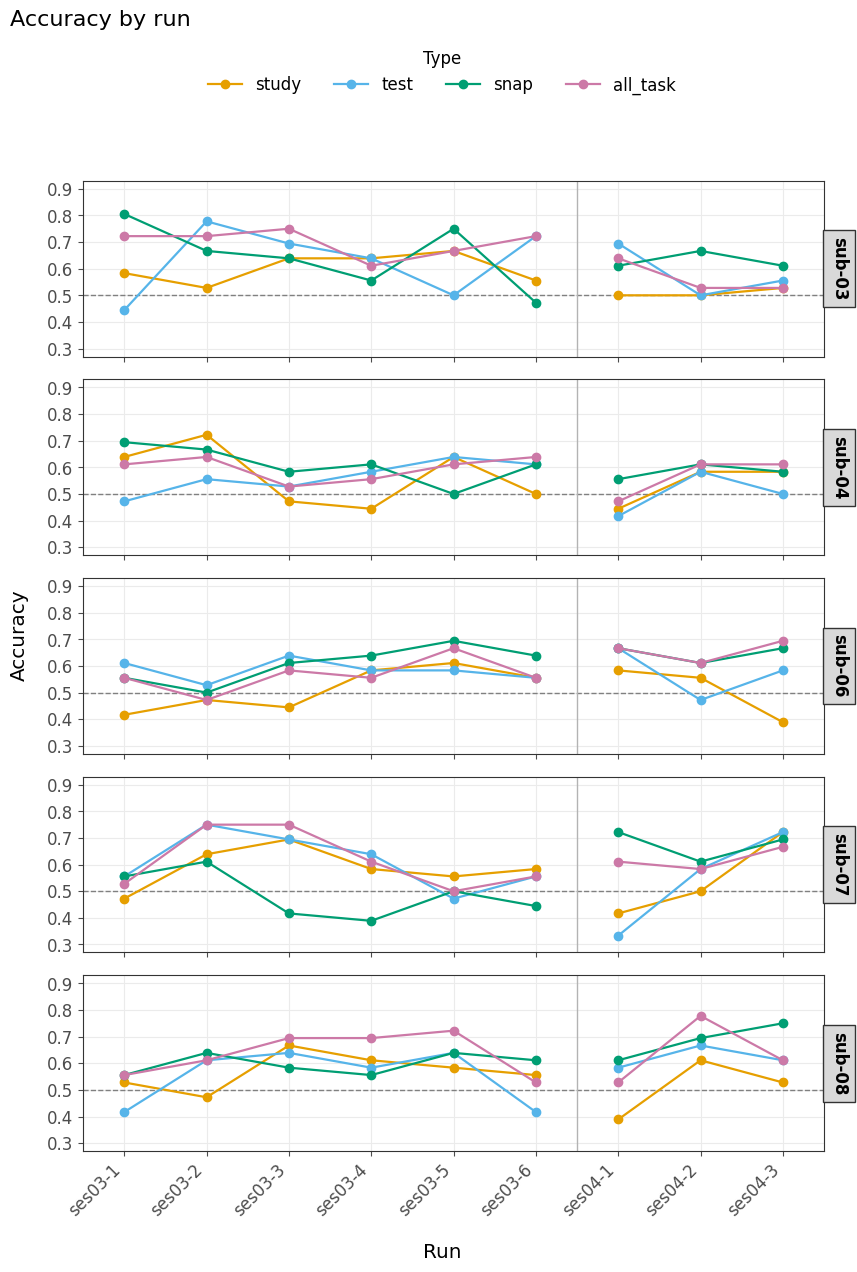

In [25]:
plot_accuracy_by_run(df)

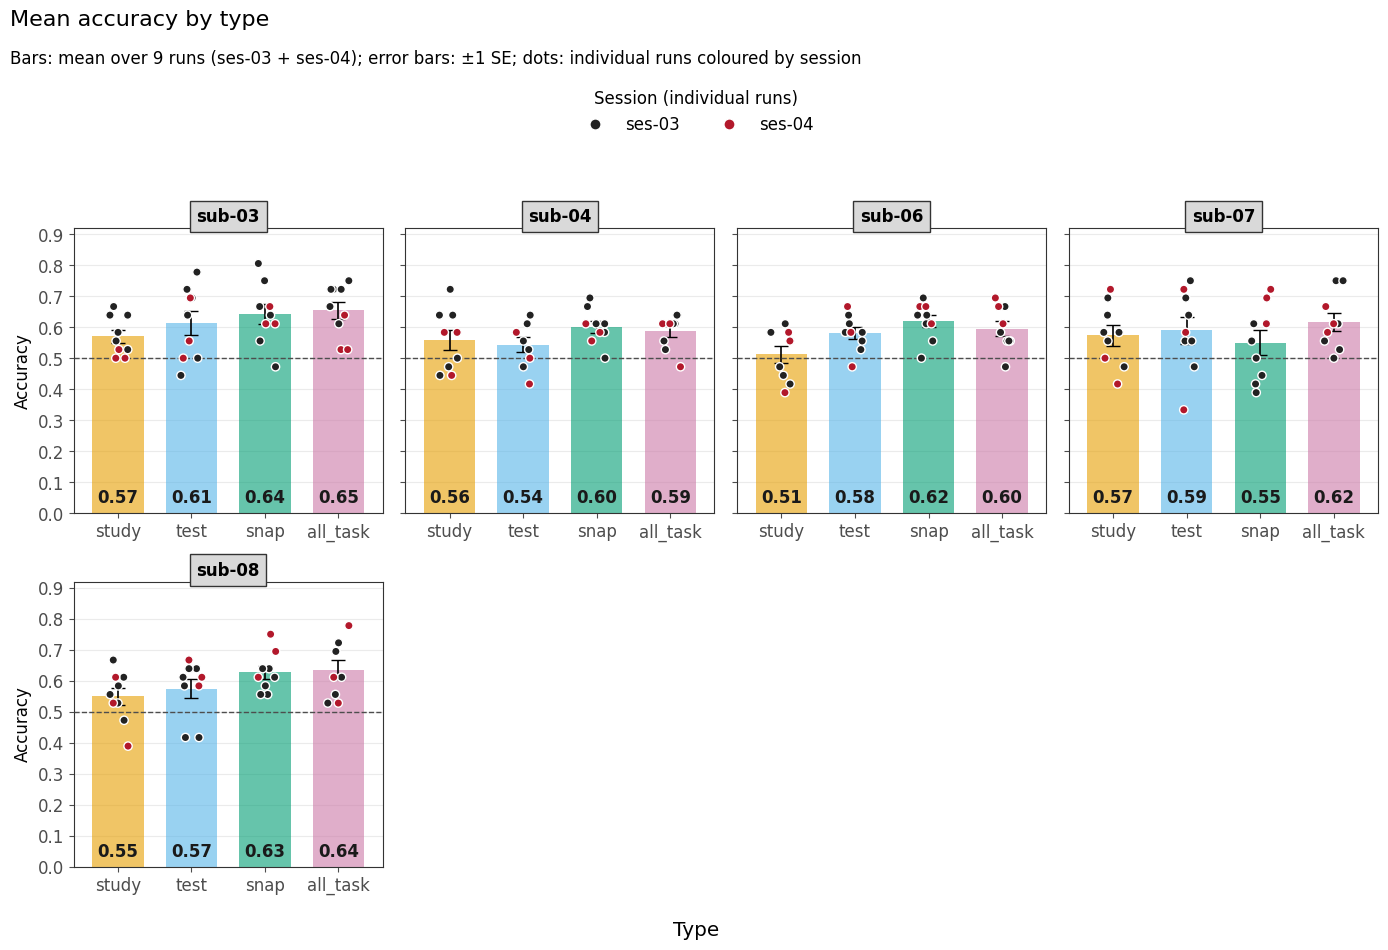

In [28]:
plot_mean_by_type(df)

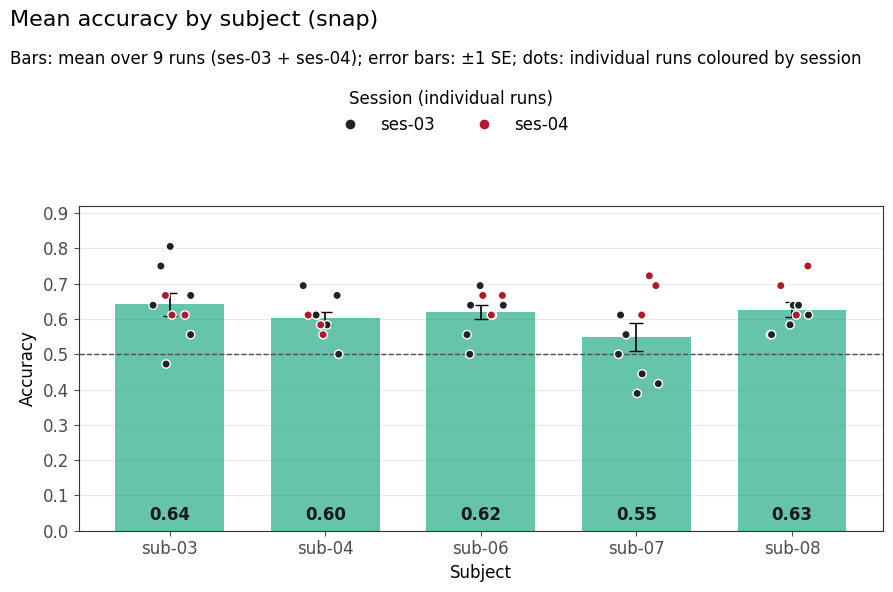

In [30]:
TYPE = "snap"
plot_accuracy_by_run(df, types=TYPE)
plot_mean_by_type(df, types=TYPE)

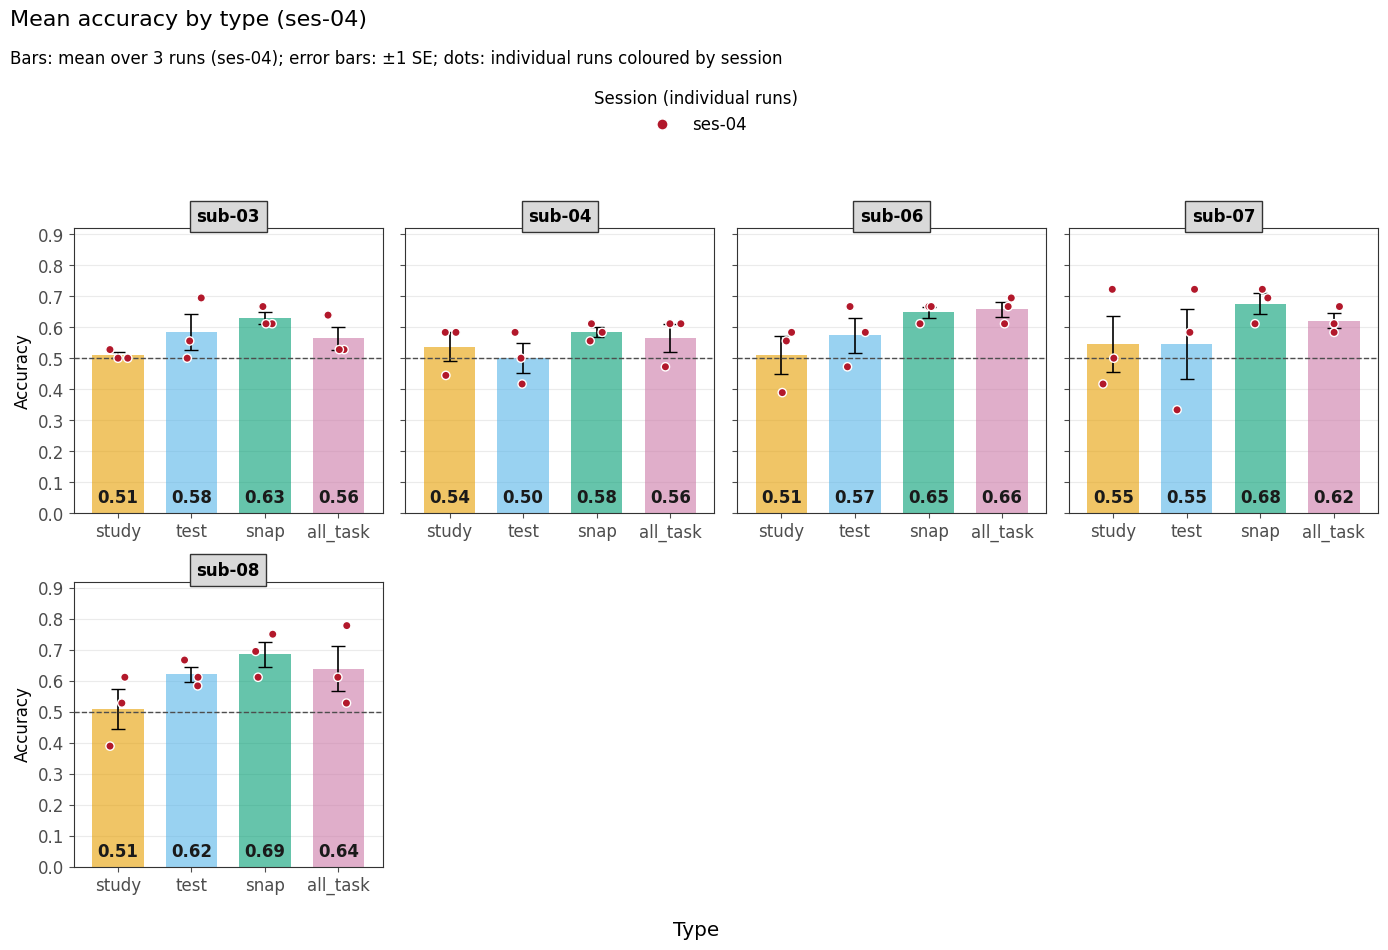

In [31]:
SESSION = "ses-04"
plot_accuracy_by_run(df, sessions=SESSION)
plot_mean_by_type(df, sessions=SESSION)